# Classifying Text — Assignment 2: cross-domain sentiment classification

## Overview

**Question:** a sentiment classifier is trained on labelled **Yelp** restaurant reviews. How well does it work on **IMDB** movie reviews, where no labels are available? And can the *unlabelled* IMDB text help?

**Pipeline:** regex cleaning, WordNet lemmatisation, `TfidfVectorizer`, `LogisticRegression`, then hyperparameter tuning with `Pipeline` + `GridSearchCV`.

**Tools:** pandas, NLTK (`WordNetLemmatizer`), scikit-learn, seaborn/matplotlib.

| Setup | Yelp accuracy (train, in-sample) | IMDB accuracy (transfer) |
|---|---|---|
| TF-IDF fitted on Yelp, logistic regression | 0.967 | 0.797 |
| Yelp vocabulary, IDF re-estimated on IMDB | – | 0.764 |
| TF-IDF fitted on Yelp + IMDB text, model trained on Yelp | 0.967 | 0.796 |
| Grid-searched TF-IDF + logistic regression | 0.971 | **0.801** |

Accuracy falls by about 17 points when moving from restaurants to movies. Part of how sentiment is expressed depends on the domain.

## Crosstraining

Test how well your model, when trained on one dataset, performs on the other.

The idea is to consider the situation where you have labels for one context, but not for the other. So you must train your model your "source context" and hope it generalizes well to your "target context", where you have no labels!

Use the two datasets available in `sentiment/yelp.csv` (online restaurant reviews from Yelp) and `sentiment/movies.csv` (online movie reviews from IMDB). Both have a column called `text` with the text of the review and a column called `positive` which should be your outcome. No other variables are needed.

To do this, make sure that you: 

1. You perform the "fitting" of both the vectorizer and the model on one of the sets
2. Use the "transform" of the vectorizer to transform the second dataset into the same feature space (X) that your model was trained on. 
3. Use the "predict" of your model to see how well it did on the second dataset. 

How well does your model generalize from one to the other? What does this say about "sentiment"?

## Crosstraining 2

Try to improve your transfer score using the unlabelled target data, P(X). What could you learn from the target context (without using the labels, only from the X) that might help you when training your model on your source context? How can you construct a feature space in your source context that generalizes better? 

> **Crosstraining 1 & 2** show the step-by-step experiments; the final tuned model is in the **Ultimate model** section.

# Data loading and cleaning

## Load data

In [ ]:
import os

# On Google Colab, mount Drive and move to the folder with the data.
# Locally, keep yelps.csv and movies.csv next to this notebook.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks')  # change to your own folder
except ImportError:
    pass

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import re

import matplotlib.pyplot as plt
import nltk
import pandas as pd
import seaborn as sns
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

yelps = pd.read_csv('yelps.csv').fillna(' ')  # Yelp restaurant reviews: source domain (labelled)
imdb = pd.read_csv('movies.csv').fillna(' ')   # IMDB movie reviews: target domain

## Label check

/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


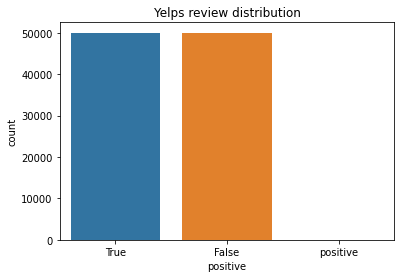

In [ ]:
sns.countplot(x=yelps.positive);
plt.title('Yelps review distribution');

In [ ]:
yelps.loc[yelps.positive == 'positive', 'positive'] = 'True'

/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


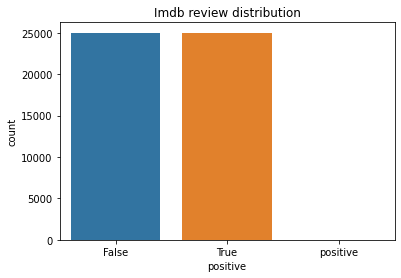

In [ ]:
sns.countplot(x=imdb.positive);
plt.title('Imdb review distribution');

In [ ]:
imdb.loc[imdb.positive == 'positive', 'positive'] = 'True'

Both datasets are roughly balanced between positive and negative reviews. A few rows had the label `'positive'` instead of `'True'`; they have been relabelled.

# Crosstraining 1: train on Yelp, test on IMDB

In [ ]:
nltk.download('wordnet')
nltk.download('omw-1.4', quiet=True)  # newer NLTK versions also need this for WordNet

lemmatizer = WordNetLemmatizer()


def preprocess(texts):
    """Regex cleaning + WordNet lemmatisation (spaCy lemmatisation was too slow for this many reviews)."""
    documents = []
    for text in texts:
        document = re.sub(r'\W', ' ', str(text))             # remove special characters
        document = re.sub(r'\s+[a-zA-Z]\s+', ' ', document)  # remove single characters
        document = re.sub(r'\^[a-zA-Z]\s+', ' ', document)   # meant for a leading single character (as written, matches a literal '^')
        document = re.sub(r'\s+', ' ', document)             # collapse whitespace
        document = re.sub(r'^b\s+', '', document)            # remove the 'b' prefix of byte strings
        document = document.lower()
        document = ' '.join(lemmatizer.lemmatize(word) for word in document.split())
        document = re.sub(r'\b\d+(?:\.\d+)?\s+', '', document)  # remove numbers
        documents.append(document)
    return documents


corpus = preprocess(yelps.text)
corpus_test = preprocess(imdb.text)

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [ ]:
vectorizer = TfidfVectorizer(min_df=2, max_df=0.8, stop_words='english', use_idf=True, norm='l2')
v = vectorizer.fit_transform(corpus)  # vocabulary and IDF learned from Yelp only

Because the vectoriser is fitted on Yelp only, its vocabulary is restaurant-specific. Words such as *food*, *restaurant* and *order* carry weight but rarely appear in movie reviews, and movie-specific words are missing altogether.

In [ ]:
y = yelps.positive
model = LogisticRegression().fit(v, y)
score = model.score(v, y)
print(f'score for train data: {score}')

score for train data: 0.9673209803705889


In [ ]:
v_test = vectorizer.transform(corpus_test)  # IMDB mapped into the Yelp feature space
y_test = imdb.positive
score = model.score(v_test, y_test)
print(f'score for test data: {score}')

score for test data: 0.7971921684698918


**Result:** 0.967 accuracy on the Yelp training data (in-sample, so optimistic) but only 0.797 on IMDB. The model fits the source domain well and transfers imperfectly. Things to try next:

1. A vocabulary that covers both domains, e.g. passing `vocabulary_` or fitting the vectoriser on both corpora.
2. Other vectorisers and classifiers, using pipelines.
3. Hyperparameter tuning, using `GridSearchCV` on the pipelines.

# Crosstraining 2: using the unlabelled IMDB text

In [ ]:
# Keep the Yelp vocabulary but re-estimate the IDF weights on the IMDB text.
vocab1 = vectorizer.vocabulary_
vectorizer_test = TfidfVectorizer(min_df=2, max_df=0.8, stop_words='english', use_idf=True, norm='l2',
                                  vocabulary=vocab1)
v_test = vectorizer_test.fit_transform(corpus_test)
vocab2 = vectorizer_test.vocabulary_

In [ ]:
score = model.score(v_test, y_test)
print(f'score for test data: {score}')

score for test data: 0.7641941483510989


Re-estimating the IDF on IMDB while keeping the Yelp vocabulary **lowers** the score (0.764). The classifier's coefficients were learned with Yelp IDF weights, so changing the weights changes what each feature means.

A better way to use the unlabelled IMDB text is to learn the vocabulary and IDF from **both** corpora (this step needs no labels) and then train the classifier on the labelled Yelp reviews only:

In [ ]:
ult_vectorizer = TfidfVectorizer(min_df=2, max_df=0.8, stop_words='english', use_idf=True, norm='l2')
ult_corpus = corpus + corpus_test
ult_vectorizer.fit(ult_corpus)  # unsupervised: vocabulary + IDF from both datasets
v_test_ult = ult_vectorizer.transform(corpus_test)
v_train_ult = ult_vectorizer.transform(corpus)
model_ult = LogisticRegression().fit(v_train_ult, y)  # supervised: Yelp labels only
score = model_ult.score(v_train_ult, y)
print(f'score for train data: {score}')
score = model_ult.score(v_test_ult, y_test)
print(f'score for test data: {score}')

score for train data: 0.9669809905702829
score for test data: 0.7957522548647081


Fitting the vectoriser on both corpora brings the transfer score back to the baseline (0.796 vs 0.797) but does not beat it. Sharing the vocabulary alone is not enough to close the domain gap. Approaches that re-weight source examples to look like the target, or that use embeddings learned on the target text (see Assignment 3), are natural next steps.

# Ultimate model

Different feature extractors and classifiers could be compared, but running pipelines for many classifiers is slow, so this section only tunes the `TfidfVectorizer` and `LogisticRegression` hyperparameters.

In [ ]:
# TF-IDF + logistic regression pipeline, tuned with 5-fold cross-validation on Yelp.
tvc_pipe = Pipeline([
    ('tvec', TfidfVectorizer()),
    ('lr', LogisticRegression()),
])

# Best values from the search rounds listed below (the saved log is from round 4: 4 penalties x 5 solvers = 20 candidates).
tf_params = {
    'tvec__min_df': [10],
    'tvec__max_df': [0.8],
    'tvec__norm': ['l2'],
    'tvec__use_idf': [True],
    'lr__penalty': ['l2'],
    'lr__solver': ['liblinear'],
}

tvc_gs = GridSearchCV(tvc_pipe, param_grid=tf_params, cv=5, verbose=1, n_jobs=-1)
tvc_gs.fit(corpus, y)
print(f'score for train data: {tvc_gs.score(corpus, y)}')
print(f'score for test data: {tvc_gs.score(corpus_test, y_test)}')

Fitting 5 folds for each of 20 candidates, totalling 100 fits


[Parallel(n_jobs=100)]: Using backend LokyBackend with 100 concurrent workers.
[Parallel(n_jobs=100)]: Done   2 out of 100 | elapsed:   52.0s remaining: 42.5min
/usr/local/lib/python3.7/dist-packages/joblib/externals/loky/process_executor.py:691: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  "timeout or by a memory leak.", UserWarning
[Parallel(n_jobs=100)]: Done 100 out of 100 | elapsed: 21.8min finished


score for train data: 0.9713108606741798
score for test data: 0.800811951282923


In [ ]:
tvc_gs.best_estimator_

Pipeline(memory=None,
         steps=[('tvec',
                 TfidfVectorizer(analyzer='word', binary=False,
                                 decode_error='strict',
                                 dtype=<class 'numpy.float64'>,
                                 encoding='utf-8', input='content',
                                 lowercase=True, max_df=0.8, max_features=None,
                                 min_df=10, ngram_range=(1, 1), norm='l2',
                                 preprocessor=None, smooth_idf=True,
                                 stop_words=None, strip_accents=None,
                                 sublinear_tf=False,
                                 token_pattern='(?u)\\b\\w\\w+\\b',
                                 tokenizer=None, use_idf=True,
                                 vocabulary=None)),
                ('lr',
                 LogisticRegression(C=1.0, class_weight=None, dual=False,
                                    fit_intercept=True, intercept_scaling=

The full grid grows multiplicatively with every parameter added, so the search was run in rounds. Each round kept the best values from the previous one. This is faster but can miss the global optimum.

| Round | Parameters searched | IMDB accuracy |
|---|---|---|
| 1 | `tvec__min_df` ∈ {0.05, 0.01, 2, 10}, `tvec__max_df` ∈ {0.9, 0.8} | 0.8007 |
| 2 | `tvec__min_df` ∈ {10, 20, 50}, `tvec__max_df` ∈ {0.8, 0.85, 0.75} | 0.8007 |
| 3 | `tvec__norm` ∈ {l1, l2}, `tvec__use_idf` ∈ {True, False} | 0.8007 |
| 4 | `lr__penalty` ∈ {l1, l2, elasticnet, none}, `lr__solver` ∈ {newton-cg, lbfgs, liblinear, sag, saga} | 0.8008 |

Tuning barely changes the transfer score (0.797 → 0.801). Larger gains would have to come from the classifier, the preprocessing or the tokeniser, or from domain-adaptation techniques.

## Summary: what does this say about sentiment?

* Within one domain, a bag-of-words model separates positive and negative Yelp reviews almost perfectly (~0.97 in-sample).
* Across domains, accuracy drops to ~0.80. Generic sentiment words (*great*, *awful*, *love*, *boring*) transfer. Domain words (*delicious*, *service*, *plot*, *acting*) do not, and some words even flip meaning between domains (*unpredictable* is good for a plot and bad for a restaurant).
* Using the unlabelled target text only to build the vocabulary did not improve transfer. Getting more out of $P(X)$ in the target domain requires methods that change *which* features the model relies on, not just which features exist.